<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# Regression Metrics - Solution

> All models are wrong, but some are useful.
>
> - <cite>George EP Box</cite>

### About
An introduction to Regression Metrics: what they are, how they work, and how use them to assess regression models in `scikit-learn`.

### Learning Objectives
- Describe the principles of regression metrics.
- Define common metrics including error measures (MAE, MSE, RMSE), R2, Adj R2 and others.
- Apply regression metrics to assess OLS models.


### Notebook Guide

- Metric #1 (Warmup): Euclidean Distance
- Prologue: Let's fit a model!
- Metric #2: Sum Squared Error (SSE)
- Metric #3: Mean Squared Error (MSE)
- Metric #4: The Coefficient of Determination (R2)
- Metric #5: Mean Absolute Deviation
- Conclusion and Takeaways

# Imports
As always... come back to this cell when you want to add more imports!

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn import metrics

# Metric #1 (Warmup): Euclidean Distance

In [ ]:
y = [4, 18, 9, 2, 7, 5]
y_hat = [3, 15, 8, 1, 8, 12]

# Euclidean distance is the square root of the sum of the squared differences between the predicted and actual values.
# It is a measure of how far off the predictions are from the actual values, and is often used as a loss function in regression problems.

In [5]:
# Compute the distance via a listcomp!
np.sqrt(sum([(yi - y_hati)**2 for yi, y_hati in zip(y, y_hat)]))

7.874007874011811

In [6]:
# Compute the distance via numpy!
y = np.array(y)
y_hat = np.array(y_hat)

np.sqrt(np.sum((y - y_hat)**2))

7.874007874011811

# Prologue: Let's fit a model!

In [7]:
# Read in ad data
ads = pd.read_csv('../data/Advertising.csv')
ads.head()

,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [ ]:
# (THREAD) Drop the unnamed column
ads.drop(columns='Unnamed: 0', inplace=True)

### Think
Look at this data. What do you think is a good question to ask that we might model?

### Quick EDA
Let's poke around this data to see what we're working with.

In [9]:
ads.dtypes

TV           float64
radio        float64
newspaper    float64
sales        float64
dtype: object

In [10]:
ads.describe()

,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [11]:
ads.isna().sum()

TV           0
radio        0
newspaper    0
sales        0
dtype: int64

In [12]:
# Create the design matrix (X) and response vector (y)
X = ads.drop(columns='sales')
y = ads.sales

In [13]:
# Fit a linear regression model
lm = LinearRegression()
lm.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0.05, 0.19,-0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['TV','radio','newspaper']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.939
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,3


In [14]:
# Create a prediction vector y_hat
y_hat = lm.predict(X)

In [ ]:
# using coef_ allows us to see the coefficients of the model, 
# which represent the change in the response variable (sales) for 
# a one-unit change in each predictor variable (TV, radio, newspaper), 
# holding all other predictors constant.
lm.coef_



array([ 0.04576465,  0.18853002, -0.00103749])

# Metric #2: Sum Squared Error (SSE)


In [ ]:
# Compute the SSE using numpy
sse = np.sum((y - y_hat)**2)
sse

# here we see that the SSE is 556.82, so the model is not a great fit for the data. 
# We can also compute the RMSE to get a sense of how far off our predictions are on average.

556.8252629021872

# Metric #3: Mean Squared Error (MSE)


In [ ]:
# Compute the MSE using numpy
mse = np.mean((y - y_hat)**2)
mse

# here we see that the MSE is 2.784, so on average, 
# our predictions are off by about 2.784 units of sales.


2.784126314510936

In [19]:
# Compute the MSE using sklearn!
metrics.mean_squared_error(y, y_hat)

2.784126314510936

### Metric #3.5: The Root Mean Squared Error (RMSE)


In [ ]:
# Compute the RMSE! Does it make sense?
np.sqrt(metrics.mean_squared_error(y, y_hat))

# the value of the RMSE is 1.668, which means that on average, 
# our predictions are off by about 1.668 units of sales. 
# This is a more interpretable metric than the MSE, as it is in the same units as the response variable (sales).

1.6685701407225697

# Metric #4: The Coefficient of Determination ($R^2$)


In [21]:
# Let's compute it "by hand"
sse = np.sum((y - y_hat)**2)
ssto = np.sum((y - np.mean(y))**2)
1 - sse / ssto

0.8972106381789522

In [22]:
# Can also compute directly via sklearn!
lm.score(X, y)

0.8972106381789522

In [23]:
# ...and via metrics
metrics.r2_score(y, y_hat)

0.8972106381789522

In [24]:
# Let's compute the SSE, MSE, RMSE of the null model.
m = y.mean()
sse = np.sum((y - m)**2)
mse = np.mean((y - m)**2)
rmse = np.sqrt(mse)

print(f"SSE = {sse}")
print(f"MSE = {mse}")
print(f"RMSE = {rmse}")

SSE = 5417.14875
MSE = 27.085743750000002
RMSE = 5.204396578855228


In [ ]:
# Compare to our OLS model:
sse = np.sum((y - y_hat)**2)
mse = metrics.mean_squared_error(y, y_hat)
rmse = np.sqrt(mse)

print(f"SSE = {sse}")
print(f"MSE = {mse}")
print(f"RMSE = {rmse}")

# As we can see from the above, the OLS model has a lower SSE, MSE, and RMSE 
# than the null model, indicating that it is a better fit for the data.
# take into account that we did not split the data into train and test sets,
# so we are evaluating the model on the same data that it was trained on. 
# This is not a good practice, as it can lead to overfitting and an overly 
# optimistic evaluation of the model's performance. In practice, we would want 
# to split the data into train and test sets, fit the model on the train set, 
# and evaluate it on the test set.

SSE = 556.8252629021872
MSE = 2.784126314510936
RMSE = 1.6685701407225697


# Metric #5: Mean Absolute Deviation


In [26]:
# Compute!
metrics.mean_absolute_error(y, y_hat)

1.2520112296870687

# Conclusion and Takeaways
In this lesson, we:

- Learned what distance metrics are (mathematically) and how they might apply to us
- Learned several regression error metrics, and why/when we might use them
- Explored the `sklearn.metrics` submodule and poked around all the different metrics it provides

### Extra: Regression Interactive Complexity

From the 05a Residuals Slide Deck, (Slide 9) but done in python

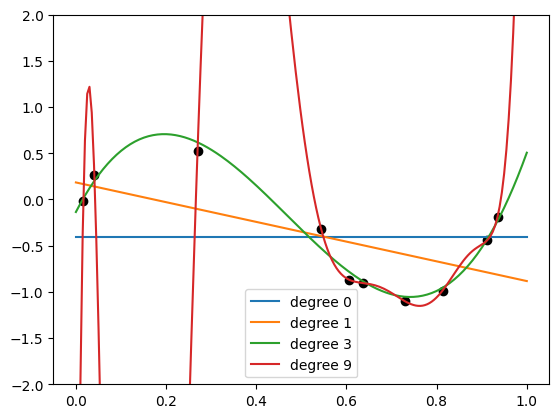

In [27]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(0)
x = np.sort(rng.uniform(0, 1, 10)); y = np.sin(2 * np.pi * x) + rng.normal(0, 0.2, 10)
grid = np.linspace(0, 1, 200)
for deg in [0, 1, 3, 9]:
    coefs = np.polyfit(x, y, deg)
    plt.plot(grid, np.polyval(coefs, grid), label=f"degree {deg}")
plt.scatter(x, y, color="black"); plt.ylim(-2, 2); plt.legend(); plt.show()

### Cross-validation
is how we find the sweet spot in practice: compute the CV error for several complexity levels (e.g. polynomial degrees) and choose the lowest.

This simulation reproduces the sine-exercise numbers from Slide 18. It draws 10,000 random pairs of points, fits both models to each pair, then measures squared bias and variance across all the fitted lines

In [28]:
import numpy as np
rng = np.random.default_rng(42)
xs = np.linspace(-1, 1, 201); truth = np.sin(np.pi * xs)
preds0, preds1 = [], []
for _ in range(10000):
    x = rng.uniform(-1, 1, 2); y = np.sin(np.pi * x)   # two random points
    preds0.append(np.full_like(xs, y.mean()))           # H0: f(x) = b
    a = (y[1] - y[0]) / (x[1] - x[0]); b = y[0] - a * x[0]
    preds1.append(a * xs + b)                            # H1: f(x) = ax + b
for name, P in [("H0", np.array(preds0)), ("H1", np.array(preds1))]:
    bias2 = np.mean((P.mean(axis=0) - truth) ** 2)
    var = np.mean(P.var(axis=0))
    print(f"{name}: bias2={bias2:.2f} var={var:.2f} total={bias2 + var:.2f}")
# Output: H0: bias2=0.50 var=0.25 total=0.74
#         H1: bias2=0.21 var=1.69 total=1.90


H0: bias2=0.50 var=0.25 total=0.74
H1: bias2=0.21 var=1.69 total=1.90
